# Projeto - Redes Neurais (análise comparativa HTR)
Roteiro completo do experimento: treina e avalia quatro arquiteturas de reconhecimento de texto manuscrito (CRNN, HTR-Flor, HTR-VT reduzido e TrOCR-small) em linhas de redações do BRESSAY e mede, além de CER e WER, a **fidelidade ortográfica**: se o modelo transcreve os erros do aluno ou os "corrige".

**Antes de rodar**
- Ativação da GPU: *Ativar → T4 GPU*.
- Envio `bressay_lines.zip` (gerado por `prepare_data.py`) para `MyDrive/` e para o caminho `MyDrive/bressay-htr/`.
- Os resultados ficam no caminho `MyDrive/htr_runs/`. Cada treino concluído é pulado se o notebook for executado de novo, então dá para retomar depois de uma desconexão.

**Seções:** 1. Dados · 2. Treino dos modelos · 3. Comparação: curva de aprendizado · 4. Resultados

## 0. Ambiente
Montagem do Google Drive, copia o repositório e os dados para o disco local do Colab (leitura mais rápida no treino) e instala as dependências que faltam no Colab.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!nvidia-smi --query-gpu=name,memory.total --format=csv

Mounted at /content/drive
name, memory.total [MiB]
Tesla T4, 15360 MiB


In [ ]:
import os, shutil
DRIVE = '/content/drive/MyDrive'
REPO  = '/content/bressay-htr'
DATA  = '/content/bressay'
RUNS  = f'{DRIVE}/htr_runs'
os.makedirs(RUNS, exist_ok=True)

if not os.path.exists(REPO):
    shutil.copytree(f'{DRIVE}/bressay-htr', REPO)
if not os.path.exists(f'{DATA}/manifest.csv'):
    !mkdir -p {DATA} && unzip -q {DRIVE}/bressay_lines.zip -d {DATA}
!pip -q install levenshtein spylls tabulate
os.chdir(REPO)
!ls {DATA} | head; wc -l {DATA}/manifest.csv

lines
manifest.csv
30091 /content/bressay/manifest.csv


## 1. Dados
Linhas do BRESSAY com a partição oficial (por página/escritor).

- Alvo = texto final do aluno: trechos riscados removidos, inserções mantidas, linhas com `@@???@@` excluídas.
- Os erros ortográficos do aluno são preservados.

In [ ]:
import pandas as pd
from PIL import Image
from src.data import load_manifest
tr, va, te = load_manifest(DATA)
print(f'treino={len(tr)}  validação={len(va)}  teste={len(te)}  | com rasura no teste: {te.has_strike.sum()}')
for _, r in te[te.has_strike == 1].head(3).iterrows():
    display(Image.open(f'{DATA}/lines/{r.id}.png'))
    print('ANOTAÇÃO:', r.raw); print('ALVO    :', r.text, '\n')

treino=19224  validação=4553  teste=5863  | com rasura no teste: 717


ANOTAÇÃO: gráfica teve o objetivo de aglutinar a nação e integrar os --é--
ALVO    : gráfica teve o objetivo de aglutinar a nação e integrar os 



ANOTAÇÃO: diversos setores sociais, especialmente durante crises. No --en--
ALVO    : diversos setores sociais, especialmente durante crises. No 



ANOTAÇÃO: que não insere os grupos mais --pode-- pobres e marginais
ALVO    : que não insere os grupos mais pobres e marginais 



## 2. Treino dos modelos
Configuração comum: entrada 40×1280 (CTC), mesmo aumento de dados, AdamW + OneCycle, parada antecipada pela CER de validação (paciência 10), decodificação gulosa sem modelo de linguagem.

In [ ]:
def run(cmd, run_name):
    if os.path.exists(f'{RUNS}/{run_name}/report.json'):
        print(f'{run_name}: já concluído, pulando'); return
    get_ipython().system(cmd)

EPOCHS = 40

In [ ]:
run(f'python -u -m src.train_ctc --model crnn  --data {DATA} --out {RUNS} --epochs {EPOCHS}', 'crnn_frac1')

crnn_frac1: já concluído, pulando


In [ ]:
run(f'python -u -m src.train_ctc --model flor  --data {DATA} --out {RUNS} --epochs {EPOCHS}', 'flor_frac1')

flor_frac1: já concluído, pulando


In [ ]:
run(f'python -u -m src.train_ctc --model htrvt --data {DATA} --out {RUNS} --epochs {EPOCHS}', 'htrvt_frac1')

htrvt_frac1: já concluído, pulando


### TrOCR-small
Primeiro sem ajuste (zero-shot, pré-treinado em inglês/IAM) e depois com fine-tuning. Avaliação final com beam search (4).

In [ ]:
run(f'python -u -m src.train_trocr --data {DATA} --out {RUNS} --zero_shot', 'trocr_zeroshot')
run(f'python -u -m src.train_trocr --data {DATA} --out {RUNS} --epochs 8', 'trocr_frac1')

trocr_zeroshot: já concluído, pulando
trocr_frac1: já concluído, pulando


## 3. Comparação: curva de aprendizado
Treino com 10%, 25% e 50% das páginas de treino (sorteio fixo, seed 42), avaliando sempre no mesmo teste. Mostra qual arquitetura depende menos de dados, o que importa para bases escolares pequenas.

In [ ]:
FRACS  = [0.1, 0.25, 0.5]
MODELS = ['crnn', 'flor', 'htrvt', 'trocr']
for f in FRACS:
    for m in [m for m in MODELS if m != 'trocr']:
        run(f'python -u -m src.train_ctc --model {m} --data {DATA} --out {RUNS} --epochs {EPOCHS} --frac {f}', f'{m}_frac{f:g}')
    if 'trocr' in MODELS:
        run(f'python -u -m src.train_trocr --data {DATA} --out {RUNS} --epochs 8 --frac {f}', f'trocr_frac{f:g}')

crnn_frac0.1: já concluído, pulando
flor_frac0.1: já concluído, pulando
htrvt_frac0.1: já concluído, pulando
trocr_frac0.1: já concluído, pulando
crnn_frac0.25: já concluído, pulando
flor_frac0.25: já concluído, pulando
htrvt_frac0.25: já concluído, pulando
trocr_frac0.25: já concluído, pulando
crnn_frac0.5: já concluído, pulando
flor_frac0.5: já concluído, pulando
htrvt_frac0.5: já concluído, pulando
trocr_frac0.5: já concluído, pulando


In [ ]:
import os, shutil
os.chdir('/content')
shutil.rmtree(REPO, ignore_errors=True)
shutil.copytree(f'{DRIVE}/bressay-htr', REPO)
os.chdir(REPO)
!ls lexicon

pt_BR.aff  pt_BR.dic


## 4. Resultados
Gera tabelas, testes de significância pareados por página, figuras e exemplos qualitativos em `MyDrive/htr_runs/_results/`.

                 Modelo Parâm. (M)             CER (%) WER (%) CER s/ rasura CER c/ rasura Acc. palavras válidas Acc. erros do aluno Sobrecorreção (%) Acc. válidas inéditas P(válida|erro) aluno P(válida|erro) inéditas CPU ms/linha Treino (min)
                   CRNN       10.1    3.89 [3.44–4.35]   15.67          3.52          6.44                  86.8                26.9              30.9                  55.4                 42.3                    20.8          289           89
               HTR-Flor        1.0    5.76 [5.19–6.37]   22.76          5.30          9.00                  80.0                26.4              19.4                  46.3                 26.4                    15.5           82           28
                 HTR-VT        5.9 11.11 [10.30–11.93]   41.54         10.49         15.47                  61.9                20.1               7.7                  32.8                  9.6                     7.7          163          132
            TrOCR-small 

## Resultados no teste (IC 95% por bootstrap de páginas)

| Modelo                  |   Parâm. (M) | CER (%)             |   WER (%) |   CER s/ rasura |   CER c/ rasura |   Acc. palavras válidas |   Acc. erros do aluno |   Sobrecorreção (%) |   Acc. válidas inéditas |   P(válida|erro) aluno |   P(válida|erro) inéditas |   CPU ms/linha |   Treino (min) |
|:------------------------|-------------:|:--------------------|----------:|----------------:|----------------:|------------------------:|----------------------:|--------------------:|------------------------:|-----------------------:|--------------------------:|---------------:|---------------:|
| CRNN                    |         10.1 | 3.89 [3.44–4.35]    |     15.67 |            3.52 |            6.44 |                    86.8 |                  26.9 |                30.9 |                    55.4 |                   42.3 |                      20.8 |            289 |             89 |
| HTR-Flor                |          1   | 5.76 [5.19–6.37]    |     22.76 |            5.3  |            9    |                    80   |                  26.4 |                19.4 |                    46.3 |                   26.4 |                      15.5 |             82 |             28 |
| HTR-VT                  |          5.9 | 11.11 [10.30–11.93] |     41.54 |           10.49 |           15.47 |                    61.9 |                  20.1 |                 7.7 |                    32.8 |                    9.6 |                       7.7 |            163 |            132 |
| TrOCR-small             |         61.6 | 6.43 [5.86–7.02]    |     18.38 |            5.8  |           10.92 |                    85   |                  16.3 |                37.6 |                    35.6 |                   45   |                      28   |           2109 |             44 |
| TrOCR-small (zero-shot) |         61.6 | 68.26 [66.70–69.69] |    110.71 |           68.08 |           69.49 |                     6.3 |                   1   |                 1.9 |                     0.9 |                    1.9 |                       1.4 |           1561 |              0 |

## CER (%) por classe de caractere

| Modelo                  |   letra s/ acento |   espaço |   pontuação/símbolo |   acento/cedilha |   dígito |   subst. só de diacrítico |
|:------------------------|------------------:|---------:|--------------------:|-----------------:|---------:|--------------------------:|
| CRNN                    |              3.7  |     0.69 |                4.33 |             4.16 |    15.52 |                       219 |
| HTR-Flor                |              5.69 |     1.13 |                6.75 |             6.02 |    24.19 |                       298 |
| HTR-VT                  |             10.28 |     1.67 |               10.55 |            12.23 |    36.9  |                       571 |
| TrOCR-small             |              6.24 |     0.9  |                5.77 |             8.19 |    17.14 |                       337 |
| TrOCR-small (zero-shot) |             61.06 |    18.74 |               60.89 |           100    |    59.27 |                      1736 |

## Teste de significância pareado

| A        | B           |   ΔCER (A−B, p.p.) | p (bootstrap pareado)   |
|:---------|:------------|-------------------:|:------------------------|
| CRNN     | HTR-Flor    |              -1.88 | < 0,001                 |
| CRNN     | HTR-VT      |              -7.23 | < 0,001                 |
| CRNN     | TrOCR-small |              -2.55 | < 0,001                 |
| HTR-Flor | HTR-VT      |              -5.35 | < 0,001                 |
| HTR-Flor | TrOCR-small |              -0.67 | < 0,001                 |
| HTR-VT   | TrOCR-small |               4.68 | < 0,001                 |



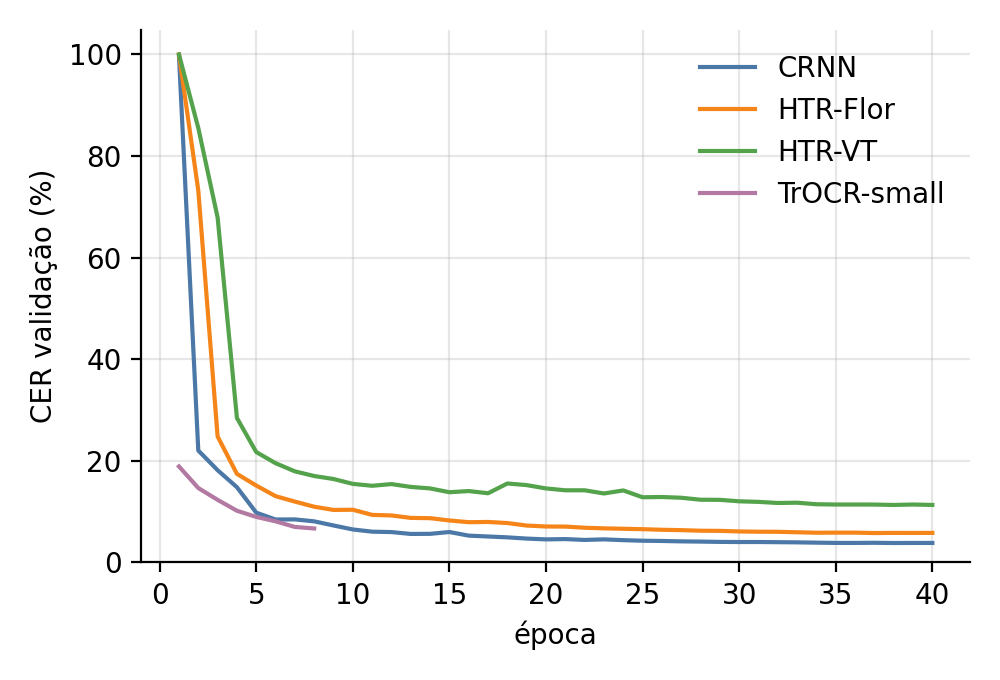

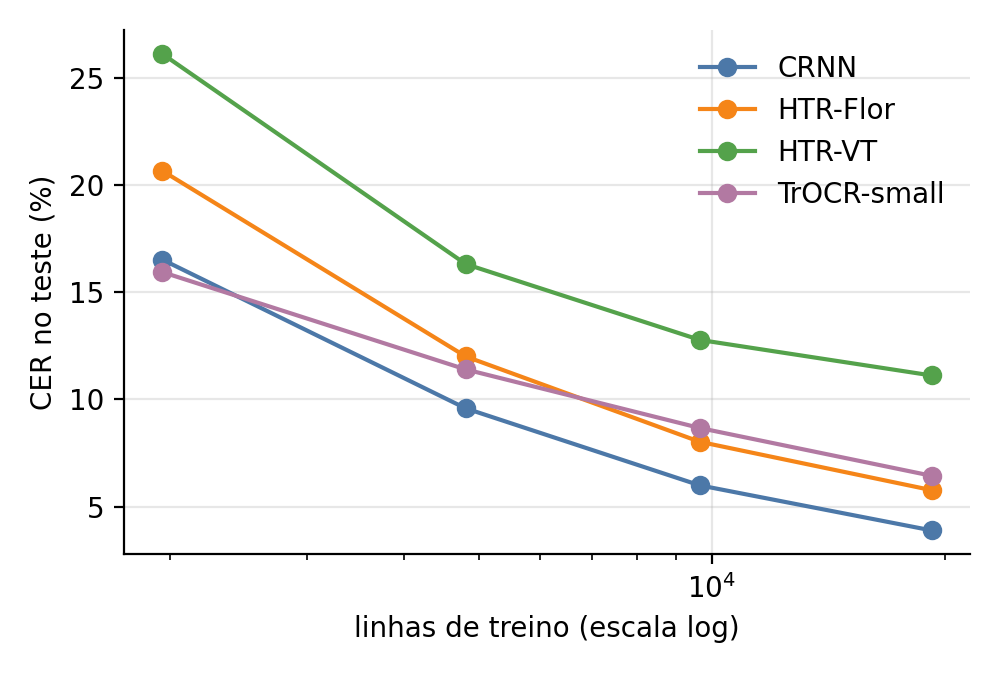

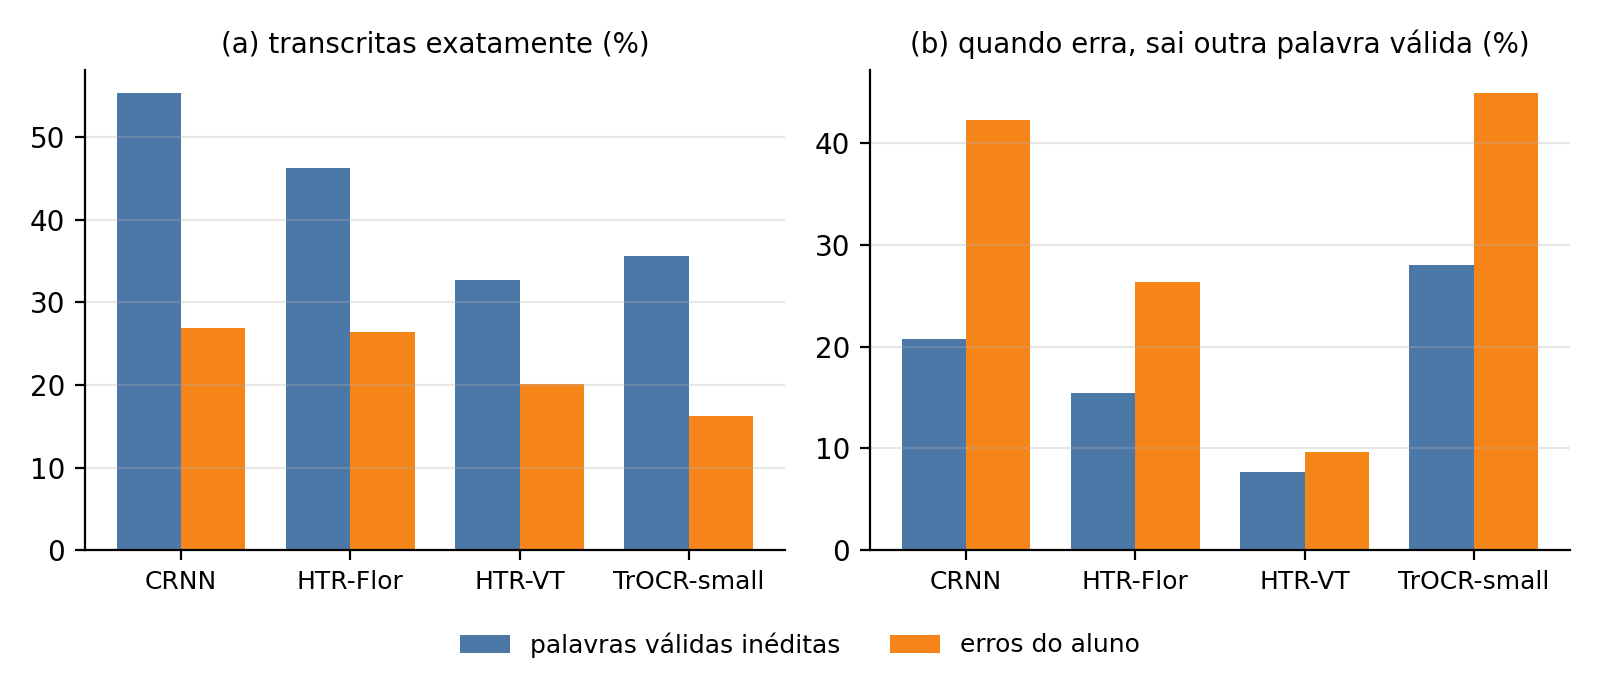

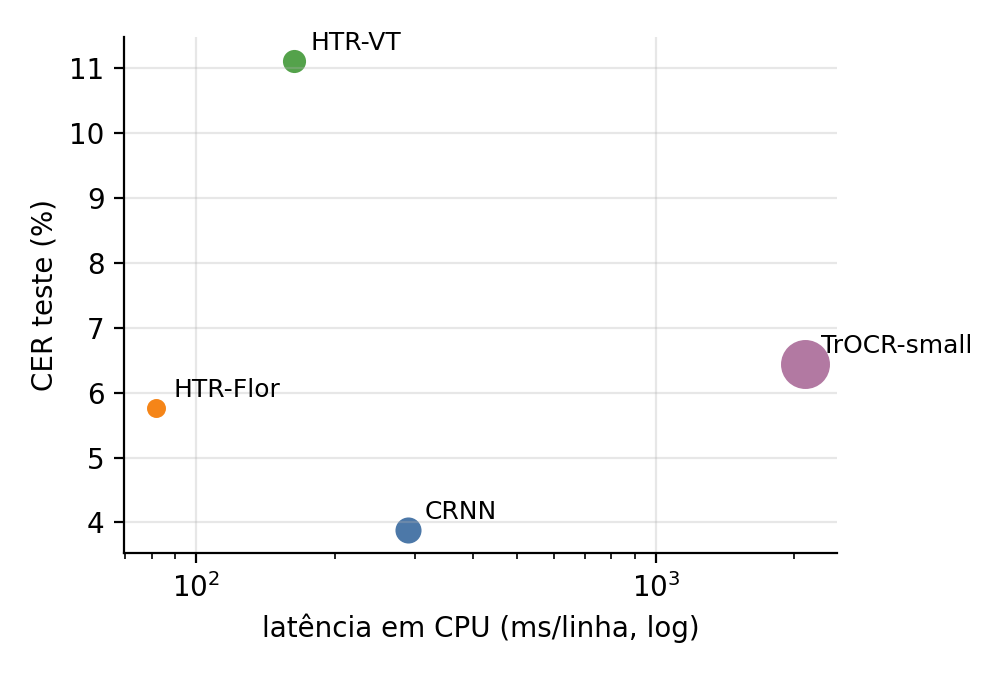

### CRNN

- `comprendido` → `compreendido`
- `recibido` → `recebido`
- `preconceotuoso` → `preconceituoso`
- `edificio` → `edifício`
- `emtre` → `entre`
- `parquiátricos` → `psiquiátricos`
- `dequela` → `daquele`
- `discursão` → `discussão`
- `precológicos` → `psicológicos`
- `trancender` → `transcender`
- `flusso` → `fluxo`
- `equilibrio` → `equilíbrio`
- `experciências` → `experiências`
- `impreceção` → `imprecisão`
- `vaniageres` → `vantagens`

### HTR-Flor

- `recibido` → `recebido`
- `preconceotuoso` → `preconceituoso`
- `edificio` → `edifício`
- `emtre` → `entre`
- `parquiátricos` → `psiquiátricos`
- `flusso` → `fluxo`
- `equilibrio` → `equilíbrio`
- `experciências` → `experiências`
- `impreceção` → `imprecisão`
- `vaniageres` → `vantagens`
- `consequênciais` → `consequências`
- `descutir` → `discutir`
- `samsa` → `sansa`
- `naturalistica` → `naturalística`
- `discusão` → `discussão`

### HTR-VT

- `recibido` → `recebido`
- `descutir` → `discuti`
- `víncula` → `vincula`
- `naturalistica` → `naturalística`
- `cidadamia` → `cidadania`
- `fornerer` → `fornecer`
- `estigna` → `estigma`
- `paradigina` → `paradigma`
- `expresão` → `expressão`
- `yoga` → `oga`
- `apciem` → `apoiem`
- `perpectiva` → `perspectivas`
- `decenças` → `doenças`
- `enraízado` → `enraizado`
- `individuos` → `indivíduos`

### TrOCR-small

- `comprendido` → `compreendido`
- `preconceotuoso` → `preconceituoso`
- `comprensão` → `compreensão`
- `emtre` → `entre`
- `parquiátricos` → `psiquiátricos`
- `discursão` → `discussão`
- `precológicos` → `psicológicos`
- `trasidas` → `brasidos`
- `trancender` → `transcender`
- `flusso` → `fluxo`
- `experciências` → `experiências`
- `frankfurt` → `Frankfurt`
- `volores` → `valores`
- `consequênciais` → `consequências`
- `naturalistica` → `naturalística`

### TrOCR-small (zero-shot)

- `prontúario` → `particular`
- `víncula` → `simula`
- `folta` → `falta`
- `perpectiva` → `perspectives`
- `perpectiva` → `perspective`
- `lalino` → `Salina`
- `line` → `fine`
- `primipal` → `principal`



### 0230-022-01-02
- **Referência:** gráfica teve o objetivo de aglutinar a nação e integrar os
- **CRNN:** gráfica teve o objetivo de agletinar a vação e integraras
- **HTR-Flor:** grófica teve, o obajetivo de aglutinar a vação e inegrar oso
- **HTR-VT:** groeica téve o oaetnvo de aglutinar a vgção e integrasr cs o
- **TrOCR-small:** gráfica teve o objetivo de aglitinar a nação e integrar os

### 0230-022-01-03
- **Referência:** diversos setores sociais, especialmente durante crises. No
- **CRNN:** versos setores sociais, especialmente clirante estres.No
- **HTR-Flor:** iversas setressociais, esecialmente lirante crtres. lo
- **HTR-VT:** iersos setorestsociais, esoecialmente curante cstsesuoe
- **TrOCR-small:** Diversos retrorestrocais, especialmente durante crises. No

### 0230-022-01-05
- **Referência:** que não insere os grupos mais pobres e marginais
- **CRNN:**  ue vão insere as grupas mais pode poeres e marginais
- **HTR-Flor:** o ue vão insere os arupas mais podes poleres e marginais
- **HTR-VT:**  ue vção insere os arupas mcis p aaeres e mnarginais
- **TrOCR-small:** o que são inserre os atuças mais poderes e margilmais

### 0230-022-01-01
- **Referência:** Na Inglaterra, o desenvolvimento da indústria cinemato-
- **CRNN:** Na Inalaterra, o desenvolvimento da indústria cinemato-
- **HTR-Flor:** NUa nalcterra, o desenvolvimento da indestria cinemato-
- **HTR-VT:** a Inalaterra, o desenvdbvimento da inaciatrua cinemato-
- **TrOCR-small:** Na Ingloterra, o desenvolvimento da indirtria cinemato-

### 0230-022-01-04
- **Referência:** entanto, no Brasil, se manteve como um espaço elitizado
- **CRNN:** entanto, no rasil, se manteve como umezaço eliizado
- **HTR-Flor:** entanto, no brasil, se manteve como um espaço eliizado
- **HTR-VT:** entanto, vo rasl, se manterve comno um espaco elijzs do
- **TrOCR-small:** entanto, no Brasil, se mantere como imperaço eliizado do

### 0230-022-01-06
- **Referência:** na dinâmica cultural moderna. Nesse sentido é indis-
- **CRNN:** na Oinâmica culttural moderna. Nesse sentidoe infis-
- **HTR-Flor:** a dinâmica cultural moderna. Nesse sentidoe indder-
- **HTR-VT:** Aa dinaâmica cuetural mocderna. esse sentiaot inadis-
- **TrOCR-small:** da dinâmica cultural moderna. Nesse sentido, indes-



In [ ]:
!python -m src.analyze --runs {RUNS} --out {RUNS}/_results --data {DATA}
from IPython.display import Markdown, Image as Img
display(Markdown(open(f'{RUNS}/_results/tabelas.md').read()))
for f in ['convergencia', 'curva_aprendizado', 'fidelidade_ortografica', 'cer_vs_custo']:
    p = f'{RUNS}/_results/{f}.png'
    if os.path.exists(p): display(Img(p, width=520))
display(Markdown(open(f'{RUNS}/_results/exemplos_sobrecorrecao.md').read()))
display(Markdown(open(f'{RUNS}/_results/exemplos_qualitativos.md').read()))